# Notebook 04 — Evaluation

**Bước 6 trong Industrial AI lifecycle.** Yêu cầu của đồ án: đánh giá ở **3 mức**.

| Mức | Câu hỏi | Chỉ số dùng trong notebook này |
|---|---|---|
| **A. Model level** | Mô hình dự đoán chính xác đến đâu? | MAE, RMSE, R², NASA score, phân tích residual |
| **B. System level** | Hệ thống cảnh báo có dùng được khi vận hành không? | False alarm, miss rate, Precision / Recall / F1, latency, computational cost, robustness |
| **C. Industrial / Business level** | Giải pháp mang lại giá trị gì cho bảo trì? | Số sự cố ngoài kế hoạch, tuổi thọ bị lãng phí, chi phí bảo trì / 1.000 chu kỳ |

Cuối notebook: **đối chiếu với tiêu chí chấp nhận đã đặt ở Notebook 01** và chọn mô hình triển khai.

> Bài giảng 03: *"Performance is more than one number"* và *"Model validation vs. Solution validation"*.

In [1]:
import os, sys

REPO_URL = "https://github.com/duyenphung206-sudo/turbofan-rul-prediction.git"
REPO_NAME = "turbofan-rul-prediction"

# Dua thu muc lam viec ve goc du an: VS Code mo tu notebooks/, Colab tai du an tu GitHub
if not os.path.exists("src"):
    if os.path.exists("../src"):
        os.chdir("..")
    else:
        if not os.path.exists(REPO_NAME):
            os.system(f"git clone -q {REPO_URL}")
        os.chdir(REPO_NAME)
        os.system("pip install -q scikit-learn==1.9.1")   # trung phien ban luc luu mo hinh
sys.path.append(os.getcwd())
print("Thu muc lam viec:", os.getcwd())

Thu muc lam viec: /tmp/nbfix


In [2]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
from tensorflow import keras

from src.rul_utils import (
    load_cmapss, load_rul, add_test_rul, prepare_features, predict_tabular, predict_lstm, make_sequences,
    regression_metrics, load_json, save_json,
    RUL_CAP, SEQ_LEN, ROLL_WINDOW, ALERT_CRITICAL, RANDOM_STATE,
    SENSOR_INFO, set_plot_style, save_fig, MODEL_COLORS, STATUS_COLORS, MUTED, INK,
)

set_plot_style()

# Du lieu, cau hinh va mo hinh
config = load_json("models/feature_config.json")
summary = load_json("reports/training_summary.json")
sensors, features = config["sensors"], config["features"]
scaler = joblib.load("models/scaler.joblib")

models = {
    "Linear Regression": joblib.load("models/linear_regression.joblib"),
    "Random Forest": joblib.load("models/random_forest.joblib"),
    "LSTM": keras.models.load_model("models/lstm.keras"),
}
MODEL_NAMES = list(models.keys())

feat_val = pd.read_csv("data/processed/val_fd001.csv.gz")
feat_test = pd.read_csv("data/processed/test_fd001.csv.gz")


def predict_all(name, feat_df):
    """Du doan RUL cho moi chu ky cua moi dong co bang mo hinh `name`."""
    if name == "LSTM":
        return predict_lstm(models[name], feat_df, sensors)
    return predict_tabular(models[name], feat_df, features)


# Du doan cho toan bo tap test va validation (moi chu ky)
for name in MODEL_NAMES:
    feat_test[name] = predict_all(name, feat_test)
    feat_val[name] = predict_all(name, feat_val)

# Danh gia chinh thuc: tai chu ky cuoi cua moi dong co test (100 diem), nhu cach NASA cung cap nhan
test_last = feat_test.groupby("unit").tail(1).reset_index(drop=True)
print("So dong co test:", len(test_last), "| So dong co LSTM chua du 30 chu ky:", int(test_last["LSTM"].isna().sum()))

So dong co test: 100 | So dong co LSTM chua du 30 chu ky: 0


## A. Model level

### A.1. Chỉ số trên tập test (100 động cơ, tại chu kỳ cuối)

- **MAE**: sai số tuyệt đối trung bình (chu kỳ) — dễ hiểu nhất với kỹ sư: "trung bình lệch bao nhiêu chu kỳ".
- **RMSE**: phạt nặng các sai số lớn — chỉ số chuẩn của các nghiên cứu trên C-MAPSS.
- **R²**: tỉ lệ biến thiên của RUL mà mô hình giải thích được.
- **NASA score** (Saxena và cs., 2008): hàm phạt **bất đối xứng** — dự đoán **muộn** (báo còn nhiều hơn thực tế) bị phạt nặng hơn dự đoán sớm, vì có thể dẫn đến hỏng trước khi kịp bảo trì. Càng thấp càng tốt.

> Nhãn RUL của tập test cũng được giới hạn ở 125 chu kỳ như khi huấn luyện (cách làm phổ biến trong các nghiên cứu trên C-MAPSS), vì mô hình được huấn luyện để trả về tối đa 125 và mọi giá trị ≥ 125 đều dẫn tới cùng một quyết định "tiếp tục vận hành".

In [3]:
y_test = test_last["RUL"]
model_level = {"Baseline (mean)": regression_metrics(y_test, np.full(len(y_test), summary["mean_rul_train"]))}
for name in MODEL_NAMES:
    model_level[name] = regression_metrics(y_test, test_last[name])

model_table = pd.DataFrame(model_level).T

# Doi chieu: RMSE khi khong gioi han nhan test o 125
rmse_uncapped = {name: regression_metrics(test_last["RUL_raw"], test_last[name])["RMSE"] for name in MODEL_NAMES}
print("RMSE neu khong gioi han nhan test o 125:", {k: round(v, 2) for k, v in rmse_uncapped.items()})
model_table.round(2)

RMSE neu khong gioi han nhan test o 125: {'Linear Regression': 18.78, 'Random Forest': 18.13, 'LSTM': 15.21}


,MAE,RMSE,R2,NASA_score
Baseline (mean),34.83,41.98,-0.10,33780.97
Linear Regression,14.07,17.49,0.81,625.57
Random Forest,12.40,16.93,0.82,762.24
LSTM,10.07,13.84,0.88,373.79


Da luu hinh: reports/figures/04_test_pred_vs_true.png


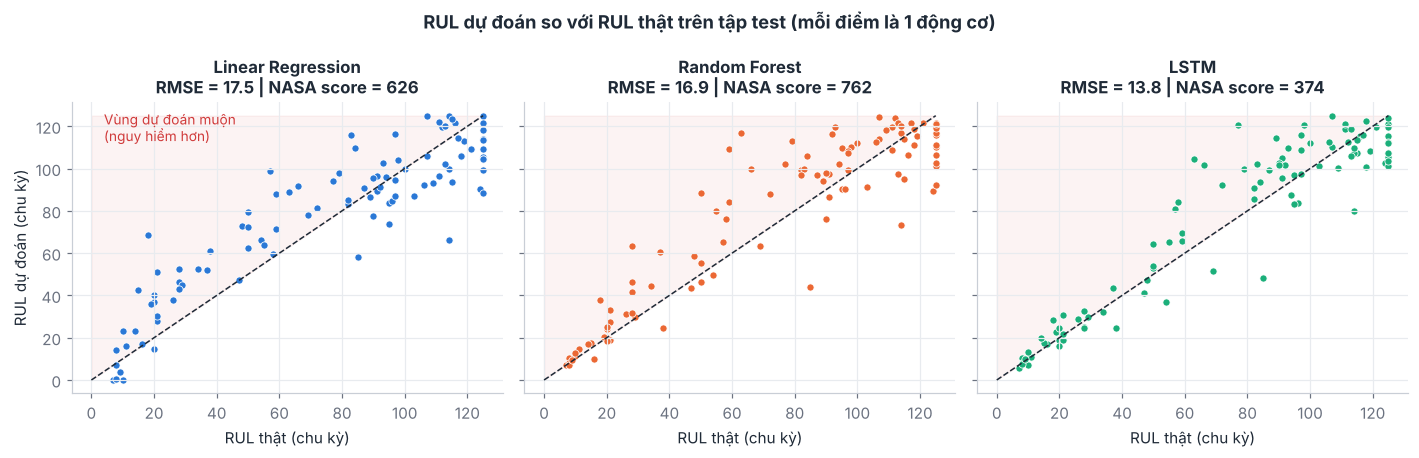

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
for ax, name in zip(axes, MODEL_NAMES):
    ax.plot([0, RUL_CAP], [0, RUL_CAP], color=INK, linestyle="--", linewidth=1)
    ax.fill_between([0, RUL_CAP], [0, RUL_CAP], [RUL_CAP, RUL_CAP], color="#d03b3b", alpha=0.06)   # vung du doan muon
    ax.scatter(y_test, test_last[name], s=22, color=MODEL_COLORS[name], edgecolor="white", linewidth=0.5)
    ax.set_title(f"{name}\nRMSE = {model_level[name]['RMSE']:.1f} | NASA score = {model_level[name]['NASA_score']:.0f}")
    ax.set_xlabel("RUL thật (chu kỳ)")
axes[0].set_ylabel("RUL dự đoán (chu kỳ)")
axes[0].text(4, 113, "Vùng dự đoán muộn\n(nguy hiểm hơn)", color="#d03b3b", fontsize=9)
fig.suptitle("RUL dự đoán so với RUL thật trên tập test (mỗi điểm là 1 động cơ)", fontweight="bold")
fig.tight_layout()
save_fig(fig, "04_test_pred_vs_true.png")
plt.show()

### A.2. Error analysis — mô hình sai **ở đâu**?

Bài giảng 03: *"For regression, do not rely only on MAE or RMSE"* → phân tích residual `e = RUL thật − RUL dự đoán` theo phân phối, theo giá trị dự đoán và theo **giai đoạn sức khỏe** của động cơ.

Da luu hinh: reports/figures/04_residual_analysis.png


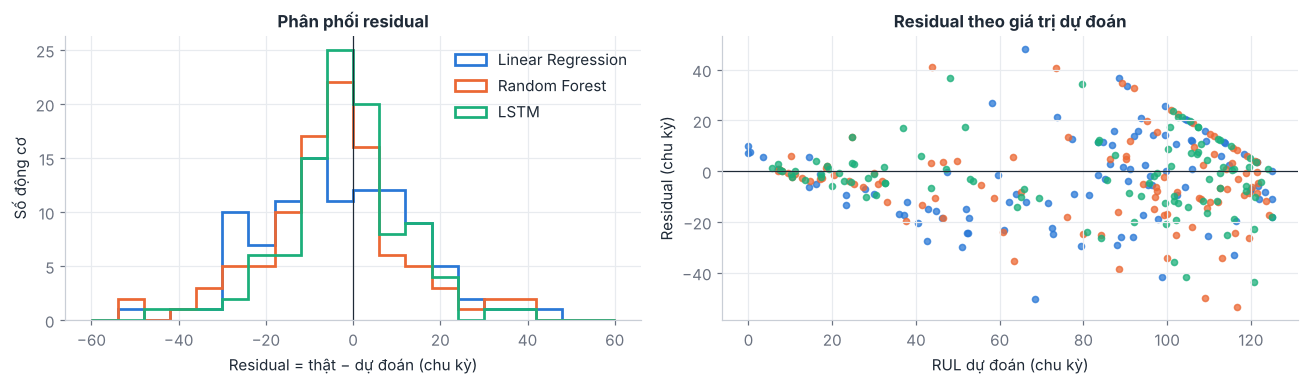

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for name in MODEL_NAMES:
    residual = y_test - test_last[name]            # e > 0: du doan som (an toan); e < 0: du doan muon
    axes[0].hist(residual, bins=np.arange(-60, 61, 6), histtype="step", linewidth=1.8, color=MODEL_COLORS[name], label=name)
    axes[1].scatter(test_last[name], residual, s=16, color=MODEL_COLORS[name], alpha=0.75, label=name)
axes[0].axvline(0, color=INK, linewidth=0.8)
axes[0].set(title="Phân phối residual", xlabel="Residual = thật − dự đoán (chu kỳ)", ylabel="Số động cơ")
axes[0].legend()
axes[1].axhline(0, color=INK, linewidth=0.8)
axes[1].set(title="Residual theo giá trị dự đoán", xlabel="RUL dự đoán (chu kỳ)", ylabel="Residual (chu kỳ)")
fig.tight_layout()
save_fig(fig, "04_residual_analysis.png")
plt.show()

In [6]:
# Sai so theo giai doan suc khoe: dung MOI chu ky cua tap test (tu chu ky 30 tro di de cong bang voi LSTM)
eval_rows = feat_test.dropna(subset=["LSTM"]).copy()
eval_rows["giai_doan"] = pd.cut(eval_rows["RUL"], bins=[-1, 30, 60, RUL_CAP],
                                labels=["RUL 0-30 (nguy cap)", "RUL 31-60 (canh bao)", "RUL 61-125 (khoe)"])
mae_by_stage = pd.DataFrame({
    name: eval_rows.groupby("giai_doan", observed=True).apply(lambda g: (g[name] - g["RUL"]).abs().mean(), include_groups=False)
    for name in MODEL_NAMES
})
mae_by_stage["so_mau"] = eval_rows.groupby("giai_doan", observed=True).size()
mae_by_stage.round(2)

,Linear Regression,Random Forest,LSTM,so_mau
giai_doan,,,,
RUL 0-30 (nguy cap),17.87,8.38,4.03,332
RUL 31-60 (canh bao),25.04,21.38,10.16,908
RUL 61-125 (khoe),14.35,13.74,10.78,8956


Da luu hinh: reports/figures/04_error_by_health_stage.png


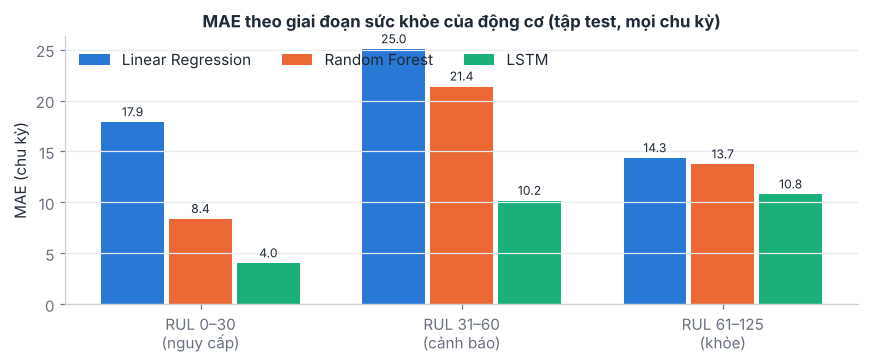

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(mae_by_stage))
for i, name in enumerate(MODEL_NAMES):
    bars = ax.bar(x + (i - 1) * 0.26, mae_by_stage[name], width=0.24, color=MODEL_COLORS[name], label=name)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
ax.set_xticks(x, ["RUL 0–30\n(nguy cấp)", "RUL 31–60\n(cảnh báo)", "RUL 61–125\n(khỏe)"])
ax.set(title="MAE theo giai đoạn sức khỏe của động cơ (tập test, mọi chu kỳ)", ylabel="MAE (chu kỳ)")
ax.grid(axis="x", visible=False)
ax.legend(ncol=3, loc="upper left")
fig.tight_layout()
save_fig(fig, "04_error_by_health_stage.png")
plt.show()

In [8]:
# Error analysis theo "industrial entity": 5 dong co test ma mo hinh tot nhat (theo RMSE) sai nhieu nhat
best_by_rmse = min(MODEL_NAMES, key=lambda n: model_level[n]["RMSE"])
worst = test_last.assign(sai_so=(test_last[best_by_rmse] - test_last["RUL"])).reindex(
    (test_last[best_by_rmse] - test_last["RUL"]).abs().sort_values(ascending=False).index).head(5)
print(f"5 dong co {best_by_rmse} du doan sai nhieu nhat (sai_so > 0 la du doan muon):")
worst[["unit", "cycle", "RUL", best_by_rmse, "sai_so"]].round(1)

5 dong co LSTM du doan sai nhieu nhat (sai_so > 0 la du doan muon):


,unit,cycle,RUL,LSTM,sai_so
66,67,71,77,120.7,43.7
78,79,101,63,104.5,41.5
92,93,244,85,48.1,-36.9
26,27,140,66,101.6,35.6
44,45,152,114,79.8,-34.2


**Nhận xét mức Model:**
- Cả ba mô hình vượt xa baseline dự đoán trung bình.
- **LSTM** có sai số thấp nhất ở mọi giai đoạn và đặc biệt thấp ở vùng **RUL 0–30** (MAE ≈ 4 chu kỳ) — đúng vùng quan trọng nhất cho quyết định bảo trì, vì khi sắp hỏng tín hiệu xuống cấp rõ nhất.
- **Random Forest** cũng chính xác ở vùng RUL 0–30 nhưng sai nhiều ở vùng 31–60, khi động cơ vừa bắt đầu xuống cấp và tín hiệu còn lẫn trong nhiễu.
- **Linear Regression** sai nhiều ngay cả ở vùng RUL 0–30 (MAE ≈ 18 chu kỳ): quan hệ tuyến tính không bám được đoạn xuống cấp nhanh ở cuối đời động cơ. RMSE toàn cục của nó chỉ kém Random Forest một chút, nhưng phân tích theo giai đoạn cho thấy nó yếu đúng ở nơi cần chính xác nhất → *"overall performance may hide weaknesses in specific conditions"*.
- Các sai số lớn nhất của LSTM đều rơi vào động cơ còn nhiều tuổi thọ (RUL thật > 60), nơi quyết định bảo trì chưa bị ảnh hưởng; tuy nhiên trong đó có các trường hợp dự đoán **muộn** hơn 35–45 chu kỳ, cần được theo dõi tiếp khi động cơ tiến gần ngưỡng cảnh báo.

### A.4. Giải thích mô hình: LSTM dựa vào cảm biến nào?

**Permutation importance** trên tập validation: xáo trộn giá trị của một cảm biến giữa các chuỗi (giữ nguyên các cảm biến khác) rồi đo RMSE tăng bao nhiêu. Cảm biến làm RMSE tăng càng nhiều thì mô hình càng dựa vào nó. Dùng validation để tập test chỉ phục vụ đánh giá cuối. Bảng kèm theo đối chiếu với độ quan trọng của Random Forest (cộng 3 đặc trưng của mỗi cảm biến).

Da luu hinh: reports/figures/04_permutation_importance.png


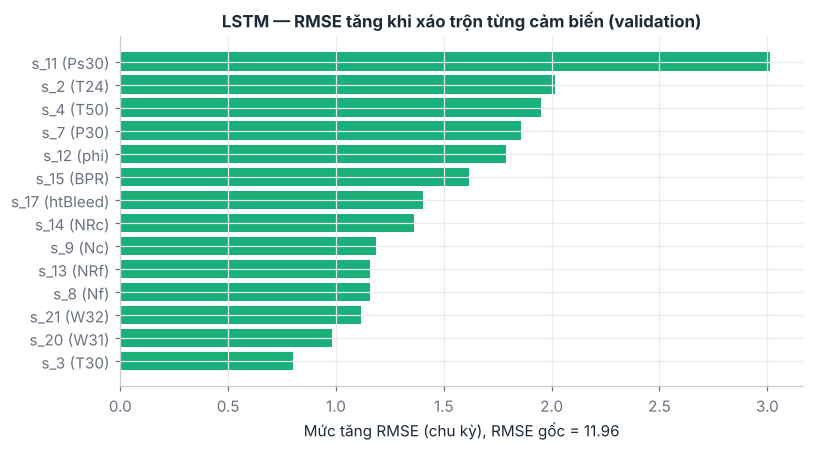

,LSTM_tang_RMSE,RF_do_quan_trong
s_11,3.015,0.053
s_2,2.017,0.048
s_4,1.953,0.017
s_7,1.859,0.012
s_12,1.787,0.011
s_15,1.616,0.009
s_17,1.402,0.014
s_14,1.363,0.028
s_9,1.186,0.105
s_13,1.160,0.024


In [9]:
# Permutation importance cua LSTM tren tap validation (tap test chi dung cho danh gia cuoi)
X_val_seq, y_val_seq, _ = make_sequences(feat_val, sensors, SEQ_LEN)
base_rmse = regression_metrics(y_val_seq, np.clip(models["LSTM"].predict(X_val_seq, verbose=0, batch_size=512).ravel(), 0, RUL_CAP))["RMSE"]
rng_pi = np.random.RandomState(RANDOM_STATE)
perm_importance = {}
for j, s in enumerate(sensors):
    X_perm = X_val_seq.copy()
    X_perm[:, :, j] = X_perm[rng_pi.permutation(len(X_perm)), :, j]     # xao tron 1 cam bien giua cac chuoi
    pred = np.clip(models["LSTM"].predict(X_perm, verbose=0, batch_size=512).ravel(), 0, RUL_CAP)
    perm_importance[s] = regression_metrics(y_val_seq, pred)["RMSE"] - base_rmse

# Doi chieu: do quan trong cua Random Forest, cong 3 dac trung (goc, trung binh truot, do lech chuan truot) cua moi cam bien
rf_imp = pd.Series(models["Random Forest"].feature_importances_, index=features)
rf_by_sensor = {s: float(rf_imp[[s, f"{s}_mean", f"{s}_std"]].sum()) for s in sensors}

pi = pd.Series(perm_importance).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh([f"{s} ({SENSOR_INFO[s][0]})" for s in pi.index], pi.values, color=MODEL_COLORS["LSTM"])
ax.set(title="LSTM — RMSE tăng khi xáo trộn từng cảm biến (validation)",
       xlabel=f"Mức tăng RMSE (chu kỳ), RMSE gốc = {base_rmse:.2f}")
fig.tight_layout()
save_fig(fig, "04_permutation_importance.png")
plt.show()
pd.DataFrame({"LSTM_tang_RMSE": perm_importance, "RF_do_quan_trong": rf_by_sensor}).sort_values("LSTM_tang_RMSE", ascending=False).round(3)

**Nhận xét:** LSTM dùng cả 14 cảm biến: xáo trộn bất kỳ cảm biến nào cũng làm RMSE tăng từ 0,8 đến 3,0 chu kỳ, mạnh nhất là Ps30 (áp suất tĩnh cửa ra HPC), đúng với dạng hỏng HPC của FD001. Nc và NRc, hai cảm biến có tương quan Spearman thấp ở Notebook 01, vẫn đóng góp 1,2–1,4 chu kỳ, xác nhận quyết định không loại chúng. Random Forest ngược lại dồn khoảng 64% độ quan trọng vào nhóm đặc trưng của một cảm biến (T30), phù hợp với việc mô hình này xấu đi nhanh khi cảm biến nhiễu (mục B.3).

## B. System level

### B.1. Chất lượng cảnh báo: false alarm và bỏ sót

Hệ thống phát cảnh báo **CRITICAL** khi `RUL dự đoán ≤ 30` chu kỳ. Đổi bài toán hồi quy thành câu hỏi vận hành: *"động cơ này có thật sự cần bảo trì ngay không?"*

| | Hệ thống báo CRITICAL | Hệ thống không báo |
|---|---|---|
| **Thật sự RUL ≤ 30** | TP — cảnh báo đúng | **FN — bỏ sót** → nguy cơ hỏng ngoài kế hoạch |
| **Thật sự RUL > 30** | **FP — báo động giả** → bảo trì sớm, lãng phí | TN |

Ngoài Precision, Recall và F1 tại ngưỡng 30 chu kỳ, **ROC-AUC** dùng RUL dự đoán làm điểm xếp hạng nguy cơ để đo khả năng phân biệt động cơ cần và không cần bảo trì mà không phụ thuộc vào ngưỡng.

In [10]:
actual_alert = y_test <= ALERT_CRITICAL
system_alert = {}
for name in MODEL_NAMES:
    predicted_alert = test_last[name] <= ALERT_CRITICAL
    tp = int((actual_alert & predicted_alert).sum())
    fp = int((~actual_alert & predicted_alert).sum())
    fn = int((actual_alert & ~predicted_alert).sum())
    tn = int((~actual_alert & ~predicted_alert).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn)
    system_alert[name] = {
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Precision": precision, "Recall": recall,
        "F1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        "ROC_AUC": float(roc_auc_score(actual_alert, -test_last[name])),   # RUL du doan cang thap, nguy co cang cao
        "False_alarm_rate": fp / (fp + tn),
        "Miss_rate": fn / (fn + tp),
    }
print(f"So dong co test thuc su can canh bao (RUL <= {ALERT_CRITICAL}): {int(actual_alert.sum())}/100")
pd.DataFrame(system_alert).T.round(3)

So dong co test thuc su can canh bao (RUL <= 30): 25/100


,TP,FP,FN,TN,Precision,Recall,F1,ROC_AUC,False_alarm_rate,Miss_rate
Linear Regression,12.0,0.0,13.0,75.0,1.000,0.48,0.649,0.992,0.000,0.52
Random Forest,18.0,1.0,7.0,74.0,0.947,0.72,0.818,0.988,0.013,0.28
LSTM,22.0,1.0,3.0,74.0,0.957,0.88,0.917,0.995,0.013,0.12


Da luu hinh: reports/figures/04_alert_confusion_matrix.png


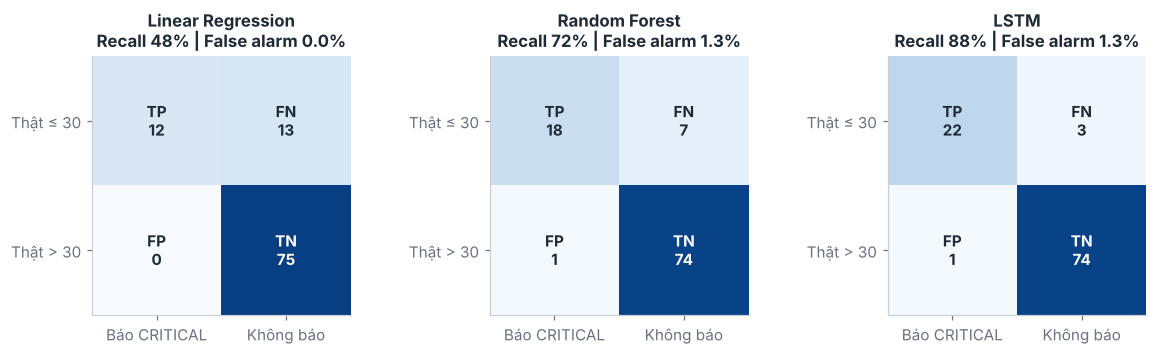

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, name in zip(axes, MODEL_NAMES):
    m = system_alert[name]
    matrix = np.array([[m["TP"], m["FN"]], [m["FP"], m["TN"]]])
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=80)
    for (i, j), v in np.ndenumerate(matrix):
        ax.text(j, i, f"{['TP', 'FN', 'FP', 'TN'][i * 2 + j]}\n{v}", ha="center", va="center",
                color="white" if v > 40 else INK, fontweight="bold")
    ax.set_xticks([0, 1], ["Báo CRITICAL", "Không báo"])
    ax.set_yticks([0, 1], ["Thật ≤ 30", "Thật > 30"])
    ax.set_title(f"{name}\nRecall {m['Recall'] * 100:.0f}% | False alarm {m['False_alarm_rate'] * 100:.1f}%")
    ax.grid(False)
fig.tight_layout()
save_fig(fig, "04_alert_confusion_matrix.png")
plt.show()

### B.2. Latency và computational cost

- **Latency**: thời gian cho **1 lần dự đoán của 1 động cơ** trên CPU (trung bình 100 lần). Yêu cầu: < 1 giây, vì dữ liệu chỉ đến một lần sau mỗi chu kỳ bay.
- **Computational cost**: thời gian huấn luyện, số tham số, dung lượng file mô hình (lấy từ Notebook 03).

> Con số latency phụ thuộc máy chạy; ý nghĩa nằm ở **bậc độ lớn** so với yêu cầu 1 giây.

In [12]:
one_row = test_last[features].iloc[[0]]
one_seq = np.zeros((1, SEQ_LEN, len(sensors)), dtype="float32")
predict_once = {
    "Linear Regression": lambda: models["Linear Regression"].predict(one_row),
    "Random Forest": lambda: models["Random Forest"].predict(one_row),
    "LSTM": lambda: models["LSTM"].predict(one_seq, verbose=0),
}

system_cost = {}
for name in MODEL_NAMES:
    predict_once[name]()                                   # chay 1 lan truoc khi do de loai thoi gian khoi tao
    t0 = time.perf_counter()
    for _ in range(100):
        predict_once[name]()
    system_cost[name] = {
        "latency_ms": (time.perf_counter() - t0) / 100 * 1000,
        "train_time_s": summary["train_info"][name]["train_time_s"],
        "n_parameters": summary["train_info"][name]["n_parameters"],
        "model_size_mb": summary["train_info"][name]["model_size_mb"],
    }
pd.DataFrame(system_cost).T.round(3)

,latency_ms,train_time_s,n_parameters,model_size_mb
Linear Regression,0.535,0.033,43.0,0.002
Random Forest,26.267,10.711,95432.0,2.228
LSTM,52.051,70.667,22337.0,0.299


### B.3. Robustness — hệ thống phản ứng thế nào khi dữ liệu xấu đi hoặc điều kiện vận hành thay đổi?

Ba phép thử, nối trực tiếp với phân tích **3B** ở Notebook 01:

| Phép thử | Mô phỏng tình huống | Liên hệ 3B |
|---|---|---|
| Cộng nhiễu Gauss vào cảm biến (2%, 5%, 10% biên độ) | Cảm biến xuống cấp, nhiễu đường truyền | **Bad Quality** |
| Xóa ngẫu nhiên 10%, 30% số đo rồi forward-fill | Mất kết nối, cảm biến hỏng tạm thời | **Broken** |
| Chạy mô hình FD001 trên tập test **FD002** (6 điều kiện vận hành) | Động cơ bay ở độ cao / tốc độ khác với lúc huấn luyện | **Background** |

Mọi phép thử đều tác động lên **dữ liệu thô**, sau đó chạy lại đúng pipeline `prepare_features` như khi triển khai.

In [13]:
test_raw = add_test_rul(load_cmapss("data/raw/test_FD001.txt"), load_rul("data/raw/RUL_FD001.txt"))
sensor_range = np.array([config["train_raw_max"][s] - config["train_raw_min"][s] for s in sensors])


def rmse_on_raw(raw_df):
    """Chay lai toan bo pipeline tren du lieu tho va tra ve RMSE tai chu ky cuoi cho ca 3 mo hinh."""
    feat = prepare_features(raw_df, sensors, scaler, ROLL_WINDOW)
    long_enough = feat.groupby("unit")["cycle"].transform("max") >= SEQ_LEN     # cong bang: cung tap dong co cho 3 mo hinh
    feat = feat[long_enough]
    last = feat.groupby("unit").tail(1)
    out = {}
    for name in MODEL_NAMES:
        pred = predict_all(name, feat).loc[last.index]
        out[name] = regression_metrics(last["RUL"], pred)["RMSE"]
    return out, last["unit"].nunique()


rng = np.random.RandomState(RANDOM_STATE)
robustness = {}

# (1) Nhieu cam bien
for level in [0.0, 0.02, 0.05, 0.10]:
    noisy = test_raw.copy()
    noisy[sensors] = noisy[sensors] + rng.normal(0, 1, noisy[sensors].shape) * (level * sensor_range)
    robustness[f"Nhieu {int(level * 100)}%"], _ = rmse_on_raw(noisy)

# (2) Mat du lieu
for frac in [0.10, 0.30]:
    broken = test_raw.copy()
    broken[sensors] = broken[sensors].mask(rng.rand(*broken[sensors].shape) < frac)
    robustness[f"Mat {int(frac * 100)}% du lieu"], _ = rmse_on_raw(broken)

# (3) Dieu kien van hanh thay doi: FD002
fd002_raw = add_test_rul(load_cmapss("data/raw/test_FD002.txt"), load_rul("data/raw/RUL_FD002.txt"))
robustness["FD002 (6 dieu kien van hanh)"], n_fd002 = rmse_on_raw(fd002_raw)

# Ti le so do FD002 nam ngoai vung du lieu da huan luyen
lo = np.array([config["train_raw_min"][s] for s in sensors])
hi = np.array([config["train_raw_max"][s] for s in sensors])
out_of_range_fd002 = float(((fd002_raw[sensors].values < lo) | (fd002_raw[sensors].values > hi)).mean())
out_of_range_fd001 = float(((test_raw[sensors].values < lo) | (test_raw[sensors].values > hi)).mean())
print(f"FD002: danh gia tren {n_fd002} dong co co >= {SEQ_LEN} chu ky")
print(f"Ti le so do nam ngoai vung da huan luyen - FD001 test: {out_of_range_fd001 * 100:.2f}% | FD002 test: {out_of_range_fd002 * 100:.1f}%")

robust_table = pd.DataFrame(robustness).T
robust_table.round(2)

FD002: danh gia tren 253 dong co co >= 30 chu ky
Ti le so do nam ngoai vung da huan luyen - FD001 test: 0.01% | FD002 test: 79.3%


,Linear Regression,Random Forest,LSTM
Nhieu 0%,17.49,16.93,13.84
Nhieu 2%,17.41,17.95,14.14
Nhieu 5%,22.93,33.23,15.63
Nhieu 10%,44.55,39.89,16.89
Mat 10% du lieu,17.29,17.99,14.87
Mat 30% du lieu,18.44,19.04,15.49
FD002 (6 dieu kien van hanh),84.20,55.52,63.08


Da luu hinh: reports/figures/04_robustness.png


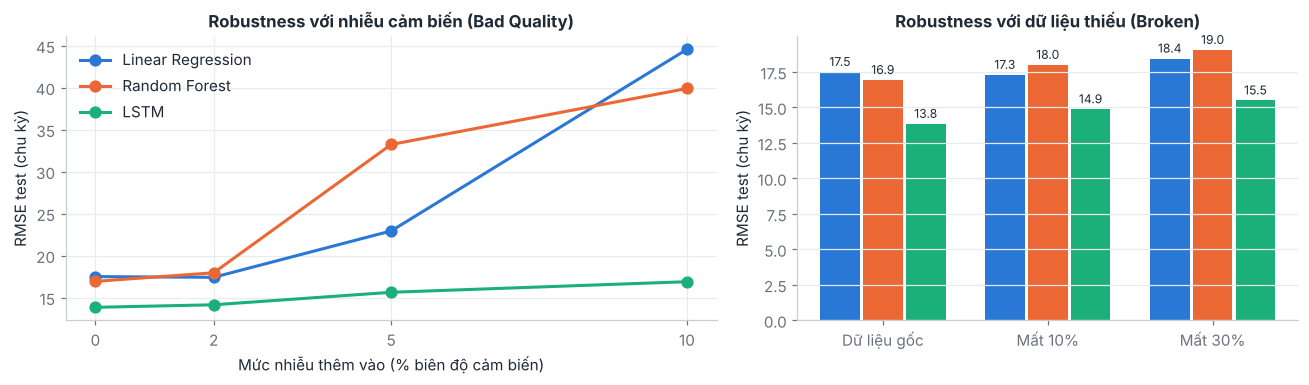

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
noise_rows = ["Nhieu 0%", "Nhieu 2%", "Nhieu 5%", "Nhieu 10%"]
for name in MODEL_NAMES:
    axes[0].plot([0, 2, 5, 10], robust_table.loc[noise_rows, name], marker="o", markersize=7, color=MODEL_COLORS[name], label=name)
axes[0].set(title="Robustness với nhiễu cảm biến (Bad Quality)", xlabel="Mức nhiễu thêm vào (% biên độ cảm biến)", ylabel="RMSE test (chu kỳ)")
axes[0].set_xticks([0, 2, 5, 10])
axes[0].legend()

x = np.arange(3)
cases = ["Nhieu 0%", "Mat 10% du lieu", "Mat 30% du lieu"]
for i, name in enumerate(MODEL_NAMES):
    bars = axes[1].bar(x + (i - 1) * 0.26, robust_table.loc[cases, name], width=0.24, color=MODEL_COLORS[name])
    axes[1].bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
axes[1].set_xticks(x, ["Dữ liệu gốc", "Mất 10%", "Mất 30%"])
axes[1].set(title="Robustness với dữ liệu thiếu (Broken)", ylabel="RMSE test (chu kỳ)")
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
save_fig(fig, "04_robustness.png")
plt.show()

**Nhận xét mức System:**
- **Cảnh báo:** xem bảng B.1 — mô hình có Recall cao hơn bỏ sót ít động cơ sắp hỏng hơn; false alarm của cả ba đều thấp.
- **Latency:** cả ba mô hình đều nhanh hơn yêu cầu 1 giây nhiều lần → latency **không phải** yếu tố phân biệt trong bài toán này.
- **Nhiễu:** Linear Regression và Random Forest xấu đi nhanh khi nhiễu tăng vì đặc trưng **độ lệch chuẩn trượt** phóng đại nhiễu; LSTM ổn định hơn rõ rệt.
- **Dữ liệu thiếu:** forward-fill giữ được chất lượng dự đoán khi mất tới 30% số đo.
- **Điều kiện vận hành thay đổi (FD002):** cả ba mô hình đều **sai nghiêm trọng**. Đây không phải lỗi của một mô hình cụ thể mà là giới hạn của dữ liệu huấn luyện (FD001 chỉ có 1 điều kiện vận hành). Hệ quả thiết kế: hệ thống **phải** kiểm tra dữ liệu đầu vào có nằm trong vùng đã huấn luyện hay không và cảnh báo người dùng (thực hiện ở trang Mô hình của app, Bước 8).

### B.4. Độ ổn định khi huấn luyện lại

Kết quả của LSTM ở trên đến từ **một lần huấn luyện** với seed 42. Để biết con số đó có phải do may mắn hay không, huấn luyện lại LSTM với 5 seed khác (cùng kiến trúc, dữ liệu, cách dừng sớm) và đánh giá trên cùng 100 động cơ test.

In [15]:
# Huan luyen lai LSTM voi 5 seed khac, giu nguyen kien truc va cach huan luyen o Notebook 03 (khoang 6 phut tren CPU)
feat_train = pd.read_csv("data/processed/train_fd001.csv.gz")
X_tr, y_tr, _ = make_sequences(feat_train, sensors, SEQ_LEN)
X_va, y_va, _ = make_sequences(feat_val, sensors, SEQ_LEN)
X_te, y_te, _ = make_sequences(feat_test, sensors, SEQ_LEN, last_only=True)

seed_rows = []
for seed in [0, 1, 2, 3, 4]:
    keras.utils.set_random_seed(seed)
    m = keras.Sequential([
        keras.layers.Input(shape=(SEQ_LEN, len(sensors))),
        keras.layers.LSTM(64),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(1),
    ])
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
    m.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=60, batch_size=128,
          callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)], verbose=0)
    pred = np.clip(m.predict(X_te, verbose=0).ravel(), 0, RUL_CAP)
    actual, alert = y_te <= ALERT_CRITICAL, pred <= ALERT_CRITICAL
    r = regression_metrics(y_te, pred)
    seed_rows.append({"seed": seed, "RMSE_test": r["RMSE"], "MAE_test": r["MAE"], "NASA_score": r["NASA_score"],
                      "Recall": float((actual & alert).sum() / actual.sum()),
                      "False_alarm_rate": float((~actual & alert).sum() / (~actual).sum())})

seed_table = pd.DataFrame(seed_rows).set_index("seed")
seed_summary = seed_table.agg(["mean", "std"])
pd.concat([seed_table, seed_summary]).round(3)

,RMSE_test,MAE_test,NASA_score,Recall,False_alarm_rate
0,13.756,9.897,364.522,0.960,0.027
1,13.805,10.673,333.422,0.920,0.013
2,13.551,10.029,326.188,0.960,0.027
3,13.984,10.897,361.472,0.800,0.013
4,13.219,9.994,303.397,0.920,0.027
mean,13.663,10.298,337.800,0.912,0.021
std,0.292,0.454,25.554,0.066,0.007


**Nhận xét:** qua 5 lần huấn luyện lại, RMSE test là 13,66 ± 0,29 chu kỳ (13,22–13,98), luôn thấp hơn Random Forest (16,93) và Linear Regression (17,49). Recall dao động 80–96% và tỉ lệ báo động giả 1,3–2,7%, nên cả 5 lần đều đạt tiêu chí Recall ≥ 80% và báo động giả ≤ 10%. Kết quả của mô hình triển khai (seed 42) nằm trong khoảng này, tức là không phải một lần chạy may mắn. Recall có độ dao động lớn nhất vì chỉ có 25 động cơ thuộc vùng cảnh báo: mỗi động cơ tương ứng 4 điểm phần trăm.

## C. Industrial / Business level

### C.1. Mô phỏng 3 chiến lược bảo trì

Dùng **20 động cơ validation** (có đầy đủ lịch sử đến lúc hỏng, không dùng để học tham số mô hình) để "phát lại" quá trình vận hành và so sánh:

| Chiến lược | Quy tắc | Điểm yếu |
|---|---|---|
| **Reactive** (chạy đến khi hỏng) | Không làm gì cho tới khi hỏng | 100% là sự cố ngoài kế hoạch |
| **Preventive** (định kỳ) | Bảo trì mọi động cơ tại một mốc chu kỳ cố định. Mốc = tuổi thọ **ngắn nhất** trong 80 động cơ train (mốc an toàn: không động cơ train nào hỏng trước mốc này) | Lãng phí tuổi thọ của động cơ còn khỏe |
| **Predictive** (theo AI) | Bảo trì ngay tại chu kỳ đầu tiên mà `RUL dự đoán ≤ 30` | Phụ thuộc độ chính xác của mô hình |

### C.2. Giả định của mô phỏng

1. **Chi phí là giả định minh họa**, không phải số liệu của một hãng cụ thể: bảo trì có kế hoạch = 1 đơn vị chi phí; sự cố ngoài kế hoạch = 5 đơn vị (đắt hơn do dừng máy đột xuất và hư hỏng lan rộng).
2. Bảo trì được thực hiện ngay tại chu kỳ có cảnh báo và đưa động cơ về trạng thái mới.
3. Chỉ số so sánh: **chi phí bảo trì trên 1.000 chu kỳ vận hành** = tổng chi phí / tổng số chu kỳ đã vận hành × 1.000.
4. 20 động cơ là mẫu nhỏ và đã được dùng để chọn siêu tham số / early stopping → kết quả mang tính **minh họa xu hướng**, không phải cam kết tiết kiệm.

In [16]:
COST_PLANNED = 1.0      # gia dinh: chi phi 1 lan bao tri co ke hoach
COST_UNPLANNED = 5.0    # gia dinh: chi phi 1 su co ngoai ke hoach

train_life = pd.read_csv("data/processed/train_fd001.csv.gz", usecols=["unit", "cycle"]).groupby("unit")["cycle"].max()
val_life = feat_val.groupby("unit")["cycle"].max()
n_engines = len(val_life)


def summarize(n_failures, used_cycles, wasted_cycles):
    """Tong hop KPI cua 1 chien luoc bao tri. wasted_cycles: so chu ky con lai (chua dung) luc bao tri."""
    n_planned = n_engines - n_failures
    total_cost = n_planned * COST_PLANNED + n_failures * COST_UNPLANNED
    return {
        "Su_co_ngoai_ke_hoach": n_failures,
        "Bao_tri_co_ke_hoach": n_planned,
        "Tuoi_tho_lang_phi_TB": float(np.mean(wasted_cycles)) if len(wasted_cycles) else 0.0,
        "Khoang_an_toan_nho_nhat": float(np.min(wasted_cycles)) if len(wasted_cycles) else 0.0,
        "Ti_le_su_dung_tuoi_tho_%": used_cycles / val_life.sum() * 100,
        "Chi_phi_tren_1000_chu_ky": total_cost / used_cycles * 1000,
    }


policy = {}

# 1) Reactive: moi dong co chay den khi hong
policy["Reactive"] = summarize(n_engines, val_life.sum(), [])

# 2) Preventive: bao tri tai moc co dinh T
T = int(train_life.min())
failed = val_life <= T
policy[f"Preventive (T={T})"] = summarize(int(failed.sum()), int(np.minimum(val_life, T).sum()), (val_life[~failed] - T).tolist())

# 3) Predictive: bao tri khi RUL du doan <= 30
for name in MODEL_NAMES:
    n_fail, used, wasted = 0, 0, []
    for unit, g in feat_val.groupby("unit"):
        alerts = g[g[name] <= ALERT_CRITICAL]
        if alerts.empty:                       # khong bao gio canh bao -> dong co hong ngoai ke hoach
            n_fail += 1
            used += g["cycle"].max()
        else:
            cycle_alert = alerts["cycle"].iloc[0]
            used += cycle_alert
            wasted.append(g["cycle"].max() - cycle_alert)
    policy[f"Predictive - {name}"] = summarize(n_fail, int(used), wasted)

policy_table = pd.DataFrame(policy).T
print(f"Tuoi tho trung binh cua 20 dong co validation: {val_life.mean():.1f} chu ky | Moc preventive T = {T}")
policy_table.round(2)

Tuoi tho trung binh cua 20 dong co validation: 203.5 chu ky | Moc preventive T = 128


,Su_co_ngoai_ke_hoach,Bao_tri_co_ke_hoach,Tuoi_tho_lang_phi_TB,Khoang_an_toan_nho_nhat,Ti_le_su_dung_tuoi_tho_%,Chi_phi_tren_1000_chu_ky
Reactive,20.0,0.0,0.00,0.0,100.00,24.57
Preventive (T=128),0.0,20.0,75.50,7.0,62.90,7.81
Predictive - Linear Regression,0.0,20.0,23.00,8.0,88.70,5.54
Predictive - Random Forest,0.0,20.0,32.65,18.0,83.96,5.85
Predictive - LSTM,0.0,20.0,29.30,22.0,85.60,5.74


Da luu hinh: reports/figures/04_maintenance_policy.png


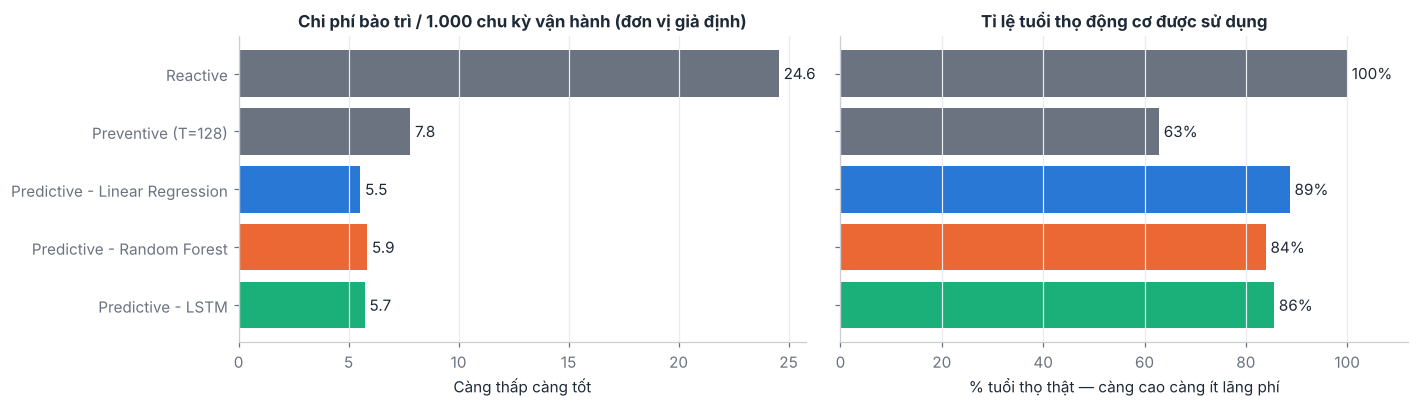

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
names = list(policy.keys())
colors = [MUTED, MUTED] + [MODEL_COLORS[n] for n in MODEL_NAMES]

bars = axes[0].barh(names[::-1], policy_table["Chi_phi_tren_1000_chu_ky"][::-1], color=colors[::-1])
axes[0].bar_label(bars, fmt="%.1f", padding=3)
axes[0].set(title="Chi phí bảo trì / 1.000 chu kỳ vận hành (đơn vị giả định)", xlabel="Càng thấp càng tốt")
axes[0].grid(axis="y", visible=False)

bars = axes[1].barh(names[::-1], policy_table["Ti_le_su_dung_tuoi_tho_%"][::-1], color=colors[::-1])
axes[1].bar_label(bars, fmt="%.0f%%", padding=3)
axes[1].set(title="Tỉ lệ tuổi thọ động cơ được sử dụng", xlabel="% tuổi thọ thật — càng cao càng ít lãng phí", xlim=(0, 112))
axes[1].set_yticklabels([])
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "04_maintenance_policy.png")
plt.show()

**Cách đọc bảng:** `Tuoi_tho_lang_phi_TB` = số chu kỳ còn dùng được nhưng bị bỏ đi do bảo trì sớm (trung bình); `Khoang_an_toan_nho_nhat` = trong 20 động cơ, lần cảnh báo **sát lúc hỏng nhất** còn cách lúc hỏng bao nhiêu chu kỳ (càng lớn càng kịp chuẩn bị).

**Nhận xét mức Industrial:**
- **Giảm downtime ngoài kế hoạch:** chiến lược predictive không để xảy ra sự cố ngoài kế hoạch nào trên 20 động cơ mô phỏng (Reactive: 20/20).
- **Giảm lãng phí / tăng productivity:** bảo trì định kỳ chỉ dùng được ≈ 63% tuổi thọ thật của động cơ; predictive dùng được ≈ 84–89% → mỗi động cơ vận hành thêm hàng chục chu kỳ trước khi phải bảo trì.
- **Giảm maintenance cost:** chi phí trên 1.000 chu kỳ của predictive thấp hơn preventive khoảng một phần tư và thấp hơn reactive khoảng ba phần tư. Khi không có sự cố nào, so sánh predictive–preventive **không phụ thuộc** vào giả định tỉ lệ chi phí 5:1 (vì cả hai chỉ gồm bảo trì có kế hoạch).
- **Chi phí thấp nhất chưa chắc là tốt nhất:** Linear Regression cho chi phí thấp nhất vì nó cảnh báo **muộn** — có động cơ chỉ được cảnh báo khi còn cách lúc hỏng chưa đến 10 chu kỳ, gần như không kịp chuẩn bị bảo trì. LSTM cảnh báo ổn định hơn (khoảng an toàn nhỏ nhất ≈ 20 chu kỳ) với chi phí gần tương đương. Đây là lý do phải xem mức Industrial **cùng với** mức System (Recall của cảnh báo).
- Kết quả cùng chiều với khoảng tiết kiệm mà Bộ Năng lượng Hoa Kỳ nêu cho predictive maintenance (8–12% so với preventive, 30–40% so với reactive — O&M Best Practices Guide) nhưng lớn hơn, vì mô phỏng này đã lý tưởng hóa: không tính chi phí cảm biến, hạ tầng dữ liệu, thời gian chờ phụ tùng. Con số ở đây **không** nên dùng làm cam kết tài chính.

### C.3. Phân tích độ nhạy

Kết quả ở C.1 phụ thuộc hai giả định: mốc bảo trì định kỳ T = 128 và tỉ lệ chi phí sự cố / bảo trì có kế hoạch = 5. Thử lại với T từ 128 đến 180 chu kỳ và tỉ lệ chi phí 3, 5, 10.

In [18]:
# Do nhay: thay doi moc bao tri dinh ky T va ti le chi phi su co / bao tri co ke hoach
def cost_per_1000(n_failures, used_cycles, ratio):
    return ((n_engines - n_failures) * COST_PLANNED + n_failures * ratio * COST_PLANNED) / used_cycles * 1000


used_lstm = policy["Predictive - LSTM"]["Ti_le_su_dung_tuoi_tho_%"] / 100 * val_life.sum()
fail_lstm = policy["Predictive - LSTM"]["Su_co_ngoai_ke_hoach"]
rows = []
for T_s in [128, 140, 150, 160, 170, 180]:
    failed = val_life <= T_s
    nf, used = int(failed.sum()), int(np.minimum(val_life, T_s).sum())
    rows.append({"Chien_luoc": f"Preventive T={T_s}", "Su_co": nf, "Ti_le_su_dung_%": used / val_life.sum() * 100,
                 **{f"Chi_phi_ti_le_{r}": cost_per_1000(nf, used, r) for r in [3, 5, 10]}})
rows.append({"Chien_luoc": "Predictive - LSTM", "Su_co": fail_lstm, "Ti_le_su_dung_%": used_lstm / val_life.sum() * 100,
             **{f"Chi_phi_ti_le_{r}": cost_per_1000(fail_lstm, used_lstm, r) for r in [3, 5, 10]}})
sensitivity = pd.DataFrame(rows).set_index("Chien_luoc")
sensitivity.round(2)

,Su_co,Ti_le_su_dung_%,Chi_phi_ti_le_3,Chi_phi_ti_le_5,Chi_phi_ti_le_10
Chien_luoc,,,,,
Preventive T=128,0,62.90,7.81,7.81,7.81
Preventive T=140,1,68.67,7.87,8.59,10.38
Preventive T=150,1,73.34,7.37,8.04,9.72
Preventive T=160,4,77.76,8.85,11.37,17.69
Preventive T=170,7,81.38,10.27,14.49,25.06
Preventive T=180,7,84.57,9.88,13.95,24.11
Predictive - LSTM,0,85.60,5.74,5.74,5.74


**Nhận xét:** nâng mốc T giúp bảo trì định kỳ dùng được nhiều tuổi thọ hơn (tới 85% ở T = 180) nhưng bắt đầu để xảy ra sự cố (7/20 động cơ ở T = 170–180). Cấu hình định kỳ rẻ nhất trong mọi trường hợp đã thử là T = 150 với tỉ lệ chi phí 3 (7,37); predictive với LSTM (5,74) vẫn rẻ hơn khoảng 22% mà không có sự cố nào. Lợi thế của bảo trì dự đoán vì vậy không phụ thuộc vào cách chọn mốc định kỳ hay tỉ lệ chi phí trong khoảng đã thử.

## D. Quyết định chấp nhận và chọn mô hình triển khai

Đối chiếu từng mô hình với **tiêu chí đã đặt ra ở Notebook 01** (Technical – Operational – Industrial).

In [19]:
preventive_cost = policy[f"Preventive (T={T})"]["Chi_phi_tren_1000_chu_ky"]
baseline_rmse = model_level["Baseline (mean)"]["RMSE"]

acceptance = {}
for name in MODEL_NAMES:
    p = policy[f"Predictive - {name}"]
    acceptance[name] = {
        "RMSE <= 20 va tot hon baseline": model_level[name]["RMSE"] <= 20 and model_level[name]["RMSE"] < baseline_rmse,
        "Recall canh bao >= 80%": system_alert[name]["Recall"] >= 0.80,
        "False alarm <= 10%": system_alert[name]["False_alarm_rate"] <= 0.10,
        "Latency < 1 giay": system_cost[name]["latency_ms"] < 1000,
        "0 su co ngoai ke hoach (mo phong)": p["Su_co_ngoai_ke_hoach"] == 0,
        "Chi phi thap hon preventive": p["Chi_phi_tren_1000_chu_ky"] < preventive_cost,
    }
acceptance_table = pd.DataFrame(acceptance)
acceptance_table.loc["Dat tat ca tieu chi"] = acceptance_table.all()
acceptance_table.replace({True: "Dat", False: "Khong dat"})

,Linear Regression,Random Forest,LSTM
RMSE <= 20 va tot hon baseline,Dat,Dat,Dat
Recall canh bao >= 80%,Khong dat,Khong dat,Dat
False alarm <= 10%,Dat,Dat,Dat
Latency < 1 giay,Dat,Dat,Dat
0 su co ngoai ke hoach (mo phong),Dat,Dat,Dat
Chi phi thap hon preventive,Dat,Dat,Dat
Dat tat ca tieu chi,Khong dat,Khong dat,Dat


In [20]:
passed = [n for n in MODEL_NAMES if all(acceptance[n].values())]
final_model = min(passed, key=lambda n: model_level[n]["RMSE"]) if passed else min(MODEL_NAMES, key=lambda n: model_level[n]["RMSE"])
print("Mo hinh dat tat ca tieu chi:", passed if passed else "khong co")
print("Mo hinh duoc chon de trien khai:", final_model)

Mo hinh dat tat ca tieu chi: ['LSTM']
Mo hinh duoc chon de trien khai: LSTM


### Kết luận lựa chọn mô hình

Mô hình được chọn là mô hình **đạt tất cả tiêu chí chấp nhận**; nếu có nhiều mô hình cùng đạt thì chọn mô hình có RMSE thấp nhất (xem kết quả in ở ô trên).

Đánh đổi cần ghi nhận khi chọn **LSTM**:

| Ưu điểm (có bằng chứng ở trên) | Hạn chế phải xử lý khi triển khai |
|---|---|
| RMSE, MAE, NASA score tốt nhất trên test | Cần **đủ 30 chu kỳ** lịch sử mới dự đoán được → app hiển thị "chưa đủ dữ liệu" cho động cơ mới |
| Recall cảnh báo cao nhất, ít bỏ sót nhất | **Khó giải thích** hơn → app bổ sung phần "cảm biến nào đang lệch khỏi trạng thái khỏe" |
| Ổn định nhất khi cảm biến nhiễu | Cần TensorFlow, huấn luyện lâu hơn (vẫn chỉ ≈ 1 phút trên CPU) |
| | Random Forest được giữ làm **mô hình dự phòng** (fallback) trong app |

Cả ba mô hình đều **không dùng được khi điều kiện vận hành thay đổi** (FD002) → hệ thống cần con người giám sát và cơ chế phát hiện dữ liệu ngoài vùng huấn luyện (Bước 8 — Monitoring).

In [21]:
# Luu ket qua danh gia: bao cao va app cung doc tu file nay
final_stage_mae = mae_by_stage[final_model].to_dict()
metrics = {
    "final_model": final_model,
    "alert_threshold": ALERT_CRITICAL,
    "model_level_test": model_level,
    "rmse_test_uncapped_labels": rmse_uncapped,
    "mae_by_health_stage_test": {name: mae_by_stage[name].to_dict() for name in MODEL_NAMES},
    "typical_error_final_model": {
        "CRITICAL": final_stage_mae["RUL 0-30 (nguy cap)"],
        "WARNING": final_stage_mae["RUL 31-60 (canh bao)"],
        "HEALTHY": final_stage_mae["RUL 61-125 (khoe)"],
    },
    "system_alert_test": system_alert,
    "system_cost": system_cost,
    "robustness_rmse": robustness,
    "out_of_range_share": {"FD001_test": out_of_range_fd001, "FD002_test": out_of_range_fd002},
    "maintenance_policy_simulation": policy,
    "policy_assumptions": {"cost_planned": COST_PLANNED, "cost_unplanned": COST_UNPLANNED,
                           "preventive_interval_T": T, "n_engines": n_engines},
    "acceptance": {n: {k: bool(v) for k, v in acceptance[n].items()} for n in MODEL_NAMES},
    "permutation_importance_lstm_val": {"base_rmse": base_rmse, "rmse_increase": perm_importance},
    "rf_importance_by_sensor": rf_by_sensor,
    "lstm_seed_stability": {"runs": seed_rows, "mean": seed_summary.loc["mean"].to_dict(), "std": seed_summary.loc["std"].to_dict()},
    "policy_sensitivity": sensitivity.reset_index().to_dict(orient="records"),
}
save_json(metrics, "reports/metrics.json")
print("Da luu reports/metrics.json")

Da luu reports/metrics.json
